In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path

# Run from the repository root or from notebooks/; raw data lives in data/raw/.
ROOT = Path.cwd() if (Path.cwd() / "data" / "raw").is_dir() else Path.cwd().parent
RAW = ROOT / "data" / "raw"
assert RAW.is_dir(), f"Raw data folder not found: {RAW}"

## 1. Read Dataset

In [3]:
customers = pd.read_csv(RAW / "olist_customers_dataset.csv")
geolocation = pd.read_csv(RAW / "olist_geolocation_dataset.csv")
order_items = pd.read_csv(RAW / "olist_order_items_dataset.csv")
payments = pd.read_csv(RAW / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(RAW / "olist_order_reviews_dataset.csv")
orders = pd.read_csv(RAW / "olist_orders_dataset.csv")
products = pd.read_csv(RAW / "olist_products_dataset.csv")
sellers = pd.read_csv(RAW / "olist_sellers_dataset.csv")
category_translation = pd.read_csv(RAW / "product_category_name_translation.csv")

## 2. Data Overview

In [4]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [5]:
geolocation.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [6]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [7]:
payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [8]:
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [9]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [10]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [11]:
sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [12]:
category_translation.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


### 1.1 Row counts, column counts, and missing values

In [13]:
datasets = {
    "customers": customers,
    "geolocation": geolocation,
    "order_items": order_items,
    "payments": payments,
    "reviews": reviews,
    "orders": orders,
    "products": products,
    "sellers": sellers,
    "category_translation": category_translation
}

overview_list = []

for name, df in datasets.items():

    missing_count = df.isna().sum().sum()
    total_cells = df.shape[0] * df.shape[1]
    missing_pct = missing_count / total_cells * 100

    overview_list.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": missing_count,
        "Missing %": round(missing_pct, 2)
    })

dataset_overview = pd.DataFrame(overview_list)

display(dataset_overview)

,Dataset,Rows,Columns,Missing Values,Missing %
0,customers,99441,5,0,0.00
1,geolocation,1000163,5,0,0.00
2,order_items,112650,7,0,0.00
3,payments,103886,5,0,0.00
4,reviews,99224,7,145903,21.01
5,orders,99441,8,4908,0.62
6,products,32951,9,2448,0.83
7,sellers,3095,4,0,0.00
8,category_translation,71,2,0,0.00


In [14]:
for name, df in datasets.items():

    missing = df.isna().sum()
    missing = missing[missing > 0]

    print("\n" + "=" * 60)
    print(name.upper())
    print("=" * 60)

    if len(missing) == 0:
        print("No missing values")
    else:
        missing_detail = pd.DataFrame({
            "Missing Count": missing,
            "Missing %": (missing / len(df) * 100).round(2)
        })

        display(missing_detail)


CUSTOMERS
No missing values

GEOLOCATION
No missing values

ORDER_ITEMS
No missing values

PAYMENTS
No missing values

REVIEWS


,Missing Count,Missing %
review_comment_title,87656,88.34
review_comment_message,58247,58.70



ORDERS


,Missing Count,Missing %
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98



PRODUCTS


,Missing Count,Missing %
product_category_name,610,1.85
product_name_lenght,610,1.85
product_description_lenght,610,1.85
product_photos_qty,610,1.85
product_weight_g,2,0.01
product_length_cm,2,0.01
product_height_cm,2,0.01
product_width_cm,2,0.01



SELLERS
No missing values

CATEGORY_TRANSLATION
No missing values


### 1.2 Duplication

In [15]:
key_check = pd.DataFrame([
    {
        "Table": "orders",
        "Rows": len(orders),
        "Key": "order_id",
        "Unique Key": orders["order_id"].nunique(),
        "Duplicate Key": orders["order_id"].duplicated().sum(),
        "Full-row Duplicates": orders.duplicated().sum()
    },
    {
        "Table": "customers",
        "Rows": len(customers),
        "Key": "customer_id",
        "Unique Key": customers["customer_id"].nunique(),
        "Duplicate Key": customers["customer_id"].duplicated().sum(),
        "Full-row Duplicates": customers.duplicated().sum()
    },
    {
        "Table": "customers",
        "Rows": len(customers),
        "Key": "customer_unique_id",
        "Unique Key": customers["customer_unique_id"].nunique(),
        "Duplicate Key": customers["customer_unique_id"].duplicated().sum(),
        "Full-row Duplicates": customers.duplicated().sum()
    },
    {
        "Table": "order_items",
        "Rows": len(order_items),
        "Key": "order_id",
        "Unique Key": order_items["order_id"].nunique(),
        "Duplicate Key": order_items["order_id"].duplicated().sum(),
        "Full-row Duplicates": order_items.duplicated().sum()
    },
    {
        "Table": "order_items",
        "Rows": len(order_items),
        "Key": "product_id",
        "Unique Key": order_items["product_id"].nunique(),
        "Duplicate Key": order_items["product_id"].duplicated().sum(),
        "Full-row Duplicates": order_items.duplicated().sum()
    },
    {
        "Table": "order_items",
        "Rows": len(order_items),
        "Key": "seller_id",
        "Unique Key": order_items["seller_id"].nunique(),
        "Duplicate Key": order_items["seller_id"].duplicated().sum(),
        "Full-row Duplicates": order_items.duplicated().sum()
    },
    {
        "Table": "products",
        "Rows": len(products),
        "Key": "product_id",
        "Unique Key": products["product_id"].nunique(),
        "Duplicate Key": products["product_id"].duplicated().sum(),
        "Full-row Duplicates": products.duplicated().sum()
    },
    {
        "Table": "sellers",
        "Rows": len(sellers),
        "Key": "seller_id",
        "Unique Key": sellers["seller_id"].nunique(),
        "Duplicate Key": sellers["seller_id"].duplicated().sum(),
        "Full-row Duplicates": sellers.duplicated().sum()
    }
])

display(key_check)

,Table,Rows,Key,Unique Key,Duplicate Key,Full-row Duplicates
0,orders,99441,order_id,99441,0,0
1,customers,99441,customer_id,99441,0,0
2,customers,99441,customer_unique_id,96096,3345,0
3,order_items,112650,order_id,98666,13984,0
4,order_items,112650,product_id,32951,79699,0
5,order_items,112650,seller_id,3095,109555,0
6,products,32951,product_id,32951,0,0
7,sellers,3095,seller_id,3095,0,0


## 2. Data Preparation for EDA

### 2.1 Overview

In [16]:
tables_used = pd.DataFrame({
    "EDA Area": [
        "Temporal patterns",
        "Customer distribution",
        "Seller distribution",
        "Product distribution",
        "Correlation and relationship exploration"
    ],
    "Tables Used": [
        "orders",
        "orders + customers",
        "orders + order_items + sellers",
        "orders + order_items + products + category_translation",
        "orders + reviews"
    ]
})

display(tables_used)

,EDA Area,Tables Used
0,Temporal patterns,orders
1,Customer distribution,orders + customers
2,Seller distribution,orders + order_items + sellers
3,Product distribution,orders + order_items + products + category_tra...
4,Correlation and relationship exploration,orders + reviews


In [17]:
join_overview = pd.DataFrame({
    "Left Table": [
        "orders",
        "orders",
        "order_items",
        "order_items",
        "products"
    ],
    "Right Table": [
        "customers",
        "order_items",
        "sellers",
        "products",
        "category_translation"
    ],
    "Join Key": [
        "customer_id",
        "order_id",
        "seller_id",
        "product_id",
        "product_category_name"
    ],
    "Purpose": [
        "Add customer location information",
        "Link orders with purchased items",
        "Add seller information",
        "Add product information",
        "Translate product category names into English"
    ]
})

display(join_overview)

,Left Table,Right Table,Join Key,Purpose
0,orders,customers,customer_id,Add customer location information
1,orders,order_items,order_id,Link orders with purchased items
2,order_items,sellers,seller_id,Add seller information
3,order_items,products,product_id,Add product information
4,products,category_translation,product_category_name,Translate product category names into English


In [18]:
orders_eda = orders.copy()
customers_eda = customers.copy()
order_items_eda = order_items.copy()
products_eda = products.copy()
sellers_eda = sellers.copy()

### 2.2 Convert purchase timestamp to datetime

In [19]:
orders_eda["order_purchase_timestamp"] = pd.to_datetime(
    orders_eda["order_purchase_timestamp"]
)

orders_eda["purchase_year_month"] = (
    orders_eda["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

orders_eda["purchase_month"] = (
    orders_eda["order_purchase_timestamp"]
    .dt.month
)

orders_eda["purchase_weekday"] = (
    orders_eda["order_purchase_timestamp"]
    .dt.day_name()
)

### 2.3 Translate product category names into English

In [20]:
products_eda = products_eda.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

### 2.4 Customer-order dataset

In [21]:
customer_order_df = orders_eda.merge(
    customers_eda,
    on="customer_id",
    how="left"
)

customer_order_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year_month,purchase_month,purchase_weekday,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,2017-10,10,Monday,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,2018-07,7,Tuesday,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,2018-08,8,Wednesday,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,2017-11,11,Saturday,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,2018-02,2,Tuesday,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


### 2.5 Seller-order-item dataset

In [22]:
seller_item_df = (
    order_items_eda
    .merge(
        sellers_eda,
        on="seller_id",
        how="left"
    )
    .merge(
        orders_eda[[
            "order_id",
            "order_purchase_timestamp",
            "purchase_year_month"
        ]],
        on="order_id",
        how="left"
    )
)

seller_item_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,seller_zip_code_prefix,seller_city,seller_state,order_purchase_timestamp,purchase_year_month
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,27277,volta redonda,SP,2017-09-13 08:59:02,2017-09
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,3471,sao paulo,SP,2017-04-26 10:53:06,2017-04
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,37564,borda da mata,MG,2018-01-14 14:33:31,2018-01
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,14403,franca,SP,2018-08-08 10:00:35,2018-08
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,87900,loanda,PR,2017-02-04 13:57:51,2017-02


### 2.6 Product-order-item dataset

In [23]:
product_item_df = (
    order_items_eda
    .merge(
        products_eda,
        on="product_id",
        how="left"
    )
    .merge(
        orders_eda[[
            "order_id",
            "order_purchase_timestamp",
            "purchase_year_month"
        ]],
        on="order_id",
        how="left"
    )
)

product_item_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,order_purchase_timestamp,purchase_year_month
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0,cool_stuff,2017-09-13 08:59:02,2017-09
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0,pet_shop,2017-04-26 10:53:06,2017-04
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0,furniture_decor,2018-01-14 14:33:31,2018-01
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0,perfumery,2018-08-08 10:00:35,2018-08
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0,garden_tools,2017-02-04 13:57:51,2017-02


## 3. EDA

### 3.1 Temporal Patterns

#### A. Monthly order volume

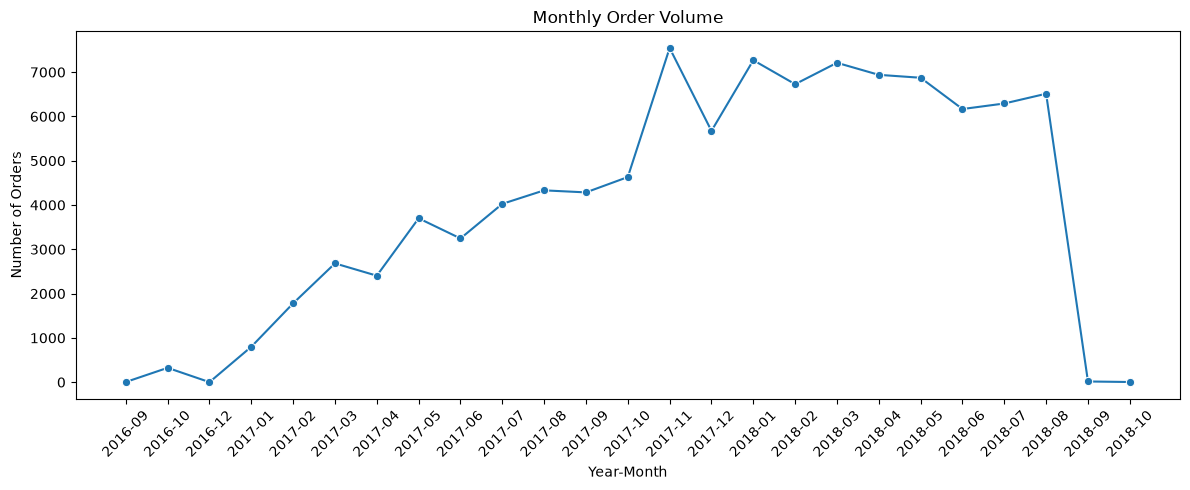

In [24]:
monthly_orders = (
    orders_eda
    .groupby("purchase_year_month")["order_id"]
    .nunique()
    .reset_index(name="order_count")
)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_orders,
    x="purchase_year_month",
    y="order_count",
    marker="o"
)

plt.title("Monthly Order Volume")
plt.xlabel("Year-Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### B. Monthly revenue

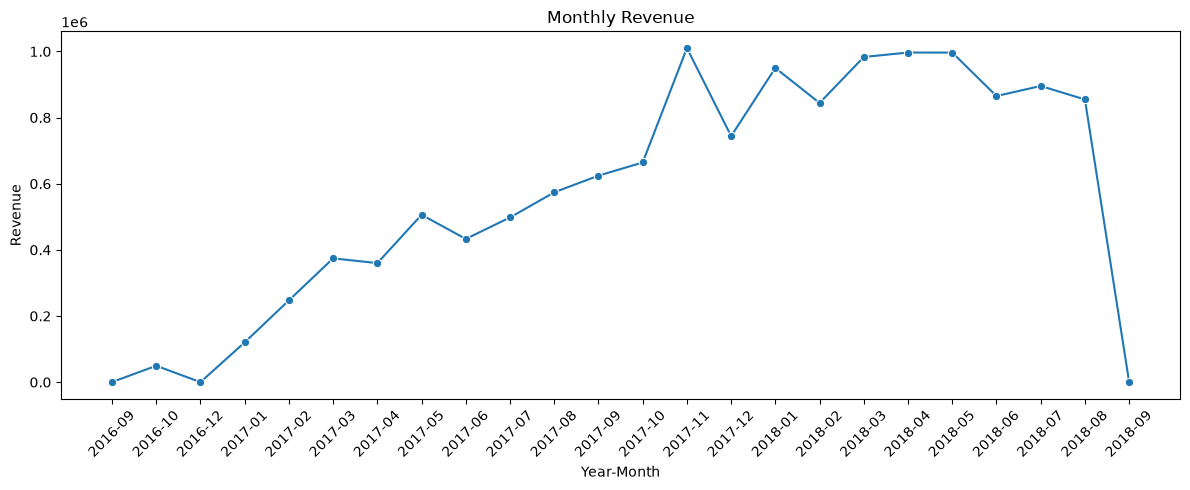

In [25]:
monthly_revenue = (
    seller_item_df
    .groupby("purchase_year_month")["price"]
    .sum()
    .reset_index(name="revenue")
)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_revenue,
    x="purchase_year_month",
    y="revenue",
    marker="o"
)

plt.title("Monthly Revenue")
plt.xlabel("Year-Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### C. Average Daily Order Volume by Weekday

,weekday,avg_daily_orders
0,Monday,174.150538
1,Tuesday,175.417582
2,Wednesday,170.901099
3,Thursday,160.445652
4,Friday,158.674157
5,Saturday,122.325843
6,Sunday,134.382022


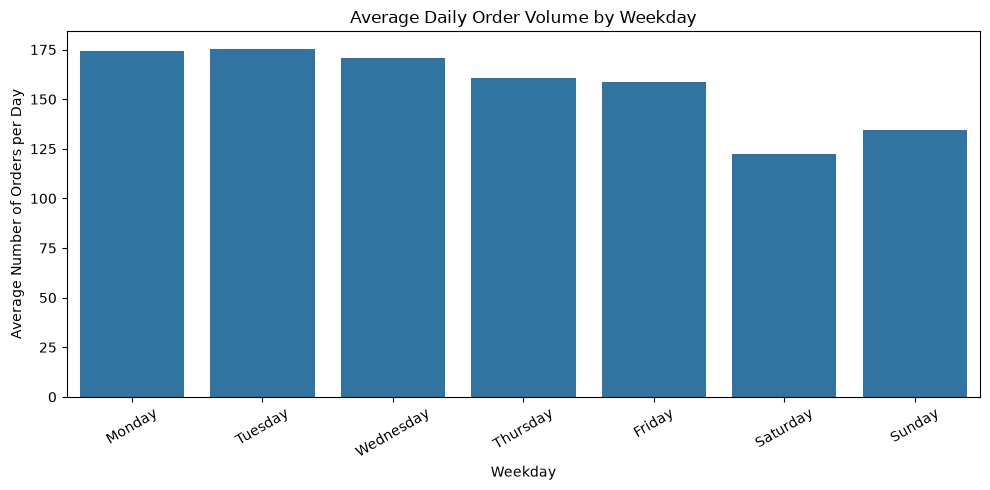

In [26]:
orders_eda["purchase_date"] = (
    orders_eda["order_purchase_timestamp"].dt.date
)


daily_orders = (
    orders_eda
    .groupby("purchase_date")["order_id"]
    .nunique()
    .reset_index(name="order_count")
)


daily_orders["purchase_date"] = pd.to_datetime(
    daily_orders["purchase_date"]
)


daily_orders["weekday"] = (
    daily_orders["purchase_date"].dt.day_name()
)


weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]


weekday_avg_orders = (
    daily_orders
    .groupby("weekday")["order_count"]
    .mean()
    .reindex(weekday_order)
    .reset_index(name="avg_daily_orders")
)

display(weekday_avg_orders)


plt.figure(figsize=(10, 5))

sns.barplot(
    data=weekday_avg_orders,
    x="weekday",
    y="avg_daily_orders"
)

plt.title("Average Daily Order Volume by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Number of Orders per Day")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

#### D. Average Hourly Order Volume

,purchase_hour,avg_hourly_orders
0,0,4.384615
1,1,2.452830
2,2,1.564417
3,3,1.353234
4,4,1.240964
5,5,1.189873
6,6,1.667774
7,7,2.705495
8,8,5.336331
9,9,8.207547


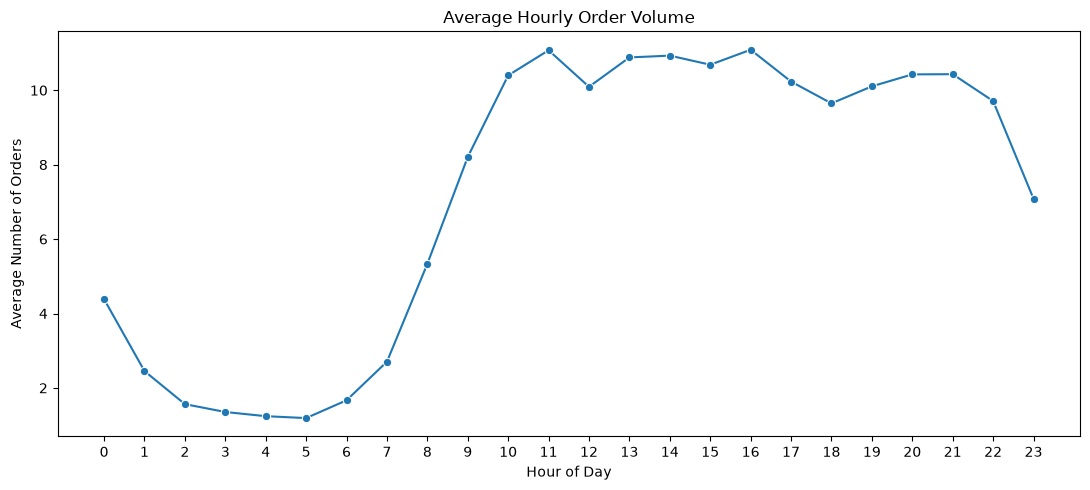

In [27]:
orders_eda["purchase_hour"] = (
    orders_eda["order_purchase_timestamp"].dt.hour
)


hourly_daily_orders = (
    orders_eda
    .groupby(["purchase_date", "purchase_hour"])["order_id"]
    .nunique()
    .reset_index(name="order_count")
)


average_hourly_orders = (
    hourly_daily_orders
    .groupby("purchase_hour")["order_count"]
    .mean()
    .reindex(range(24), fill_value=0)
    .reset_index(name="avg_hourly_orders")
)

display(average_hourly_orders)


plt.figure(figsize=(11, 5))

sns.lineplot(
    data=average_hourly_orders,
    x="purchase_hour",
    y="avg_hourly_orders",
    marker="o"
)

plt.title("Average Hourly Order Volume")
plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Orders")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

### 3.2 Customer Distribution

#### A. Unique customers by state

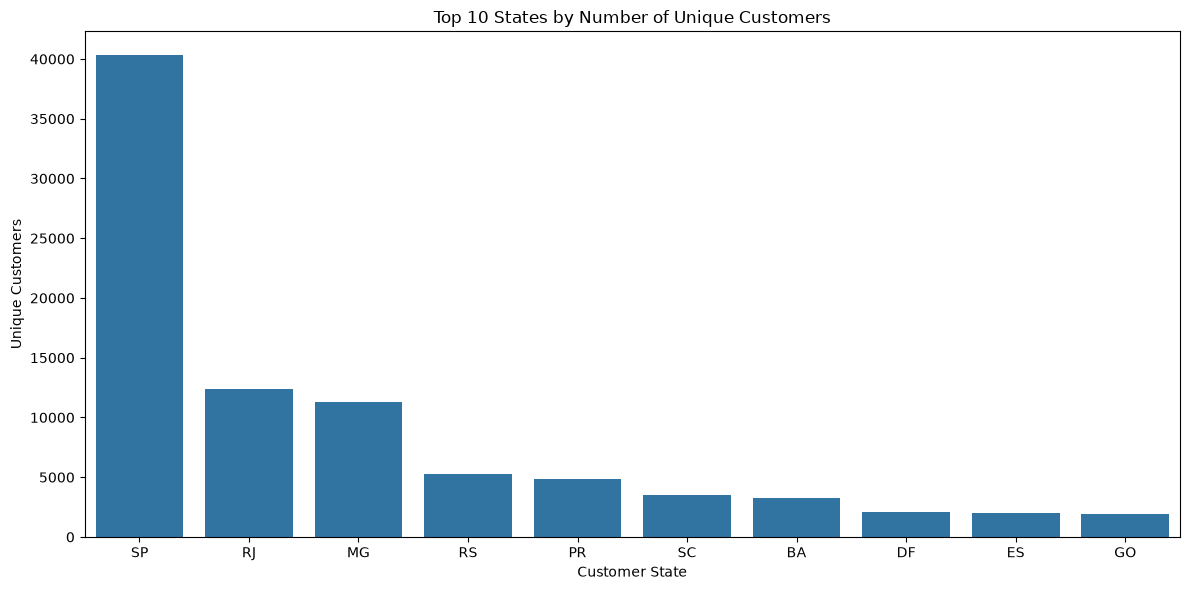

In [28]:
customers_by_state = (
    customer_order_df
    .groupby("customer_state")["customer_unique_id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="unique_customers")
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=customers_by_state.head(10),
    x="customer_state",
    y="unique_customers"
)

plt.title("Top 10 States by Number of Unique Customers")
plt.xlabel("Customer State")
plt.ylabel("Unique Customers")
plt.tight_layout()
plt.show()

#### B. Orders by customer state

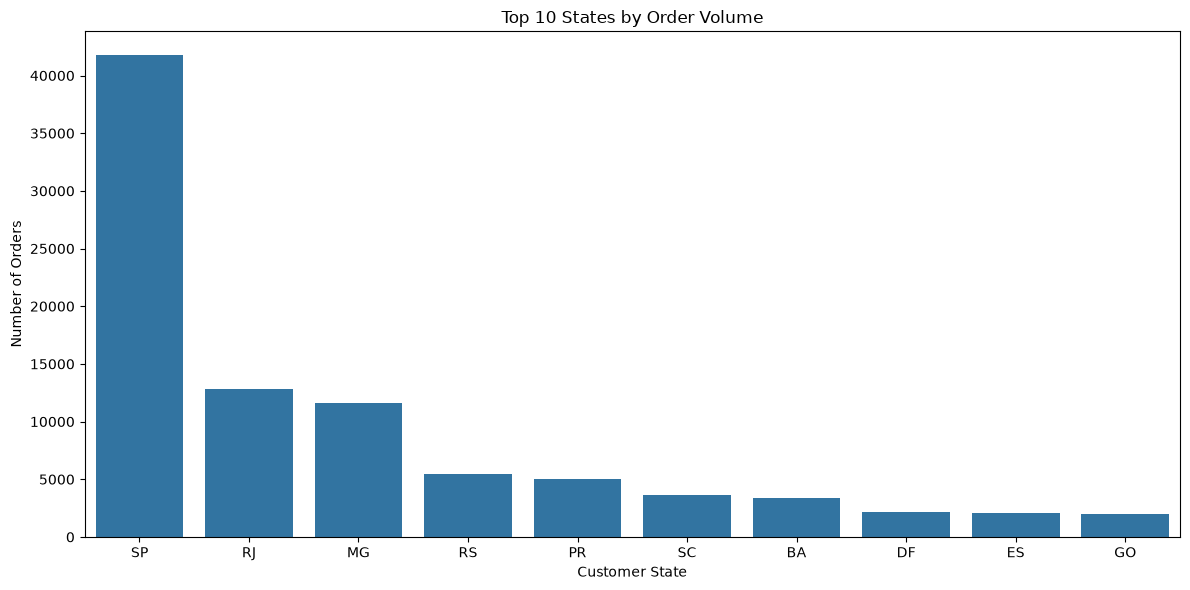

In [29]:
orders_by_state = (
    customer_order_df
    .groupby("customer_state")["order_id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="order_count")
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=orders_by_state.head(10),
    x="customer_state",
    y="order_count"
)

plt.title("Top 10 States by Order Volume")
plt.xlabel("Customer State")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

#### C. Repeat customer distribution

In [30]:
orders_per_customer = (
    customer_order_df
    .groupby("customer_unique_id")["order_id"]
    .nunique()
)

repeat_distribution = (
    orders_per_customer
    .value_counts()
    .sort_index()
    .reset_index()
)

repeat_distribution.columns = [
    "number_of_orders",
    "number_of_customers"
]

display(repeat_distribution.head(10))

repeat_customer_rate = (
    (orders_per_customer > 1).mean() * 100
)

print(
    f"Repeat customer rate: "
    f"{repeat_customer_rate:.2f}%"
)

,number_of_orders,number_of_customers
0,1,93099
1,2,2745
2,3,203
3,4,30
4,5,8
5,6,6
6,7,3
7,9,1
8,17,1


Repeat customer rate: 3.12%


### 3.3 SELLER DISTRIBUTION

##### A. Number of sellers by state

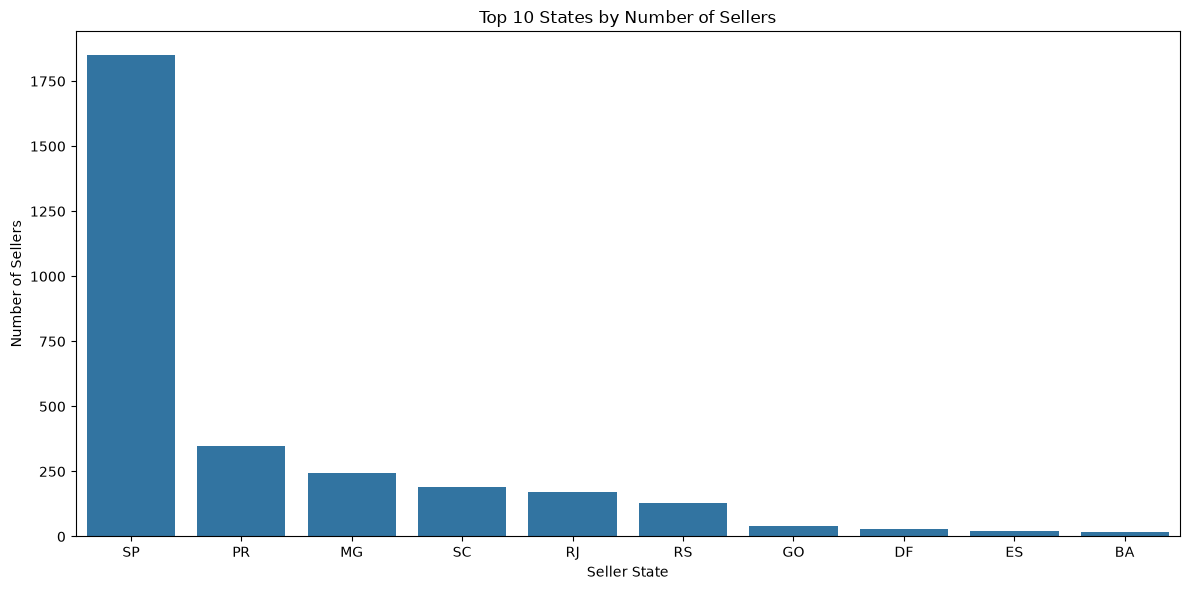

In [31]:
sellers_by_state = (
    sellers_eda
    .groupby("seller_state")["seller_id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="seller_count")
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=sellers_by_state.head(10),
    x="seller_state",
    y="seller_count"
)

plt.title("Top 10 States by Number of Sellers")
plt.xlabel("Seller State")
plt.ylabel("Number of Sellers")
plt.tight_layout()
plt.show()


##### B. Order volume by seller state

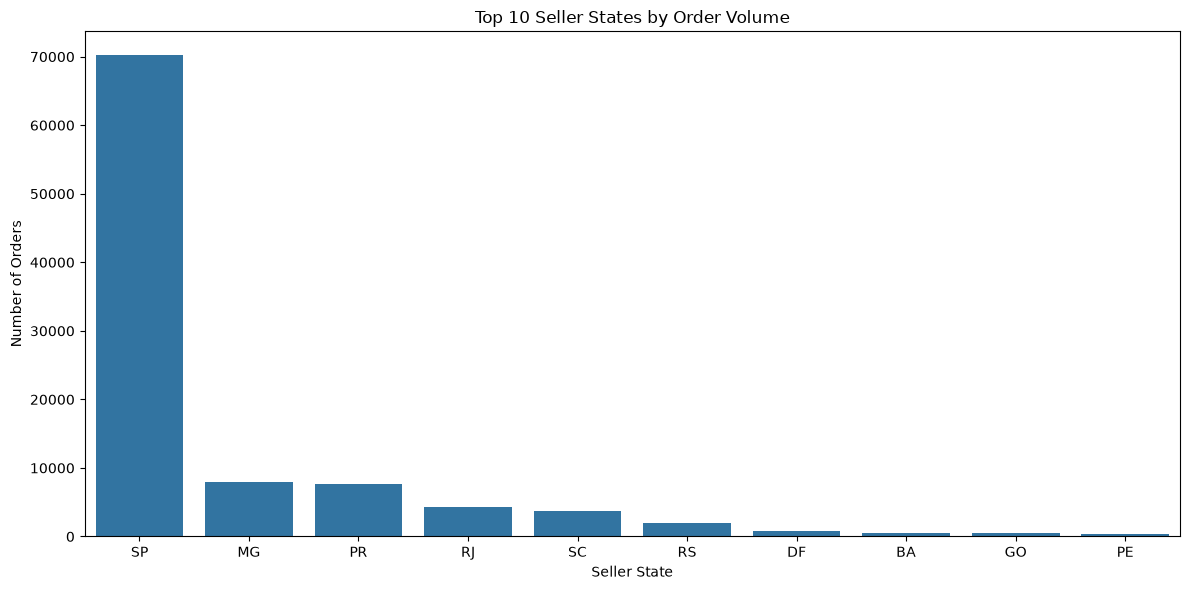

In [32]:
seller_orders_by_state = (
    seller_item_df
    .groupby("seller_state")["order_id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="order_count")
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=seller_orders_by_state.head(10),
    x="seller_state",
    y="order_count"
)

plt.title("Top 10 Seller States by Order Volume")
plt.xlabel("Seller State")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()


### 3.4 PRODUCT DISTRIBUTION

#### A. Top product categories by item volume

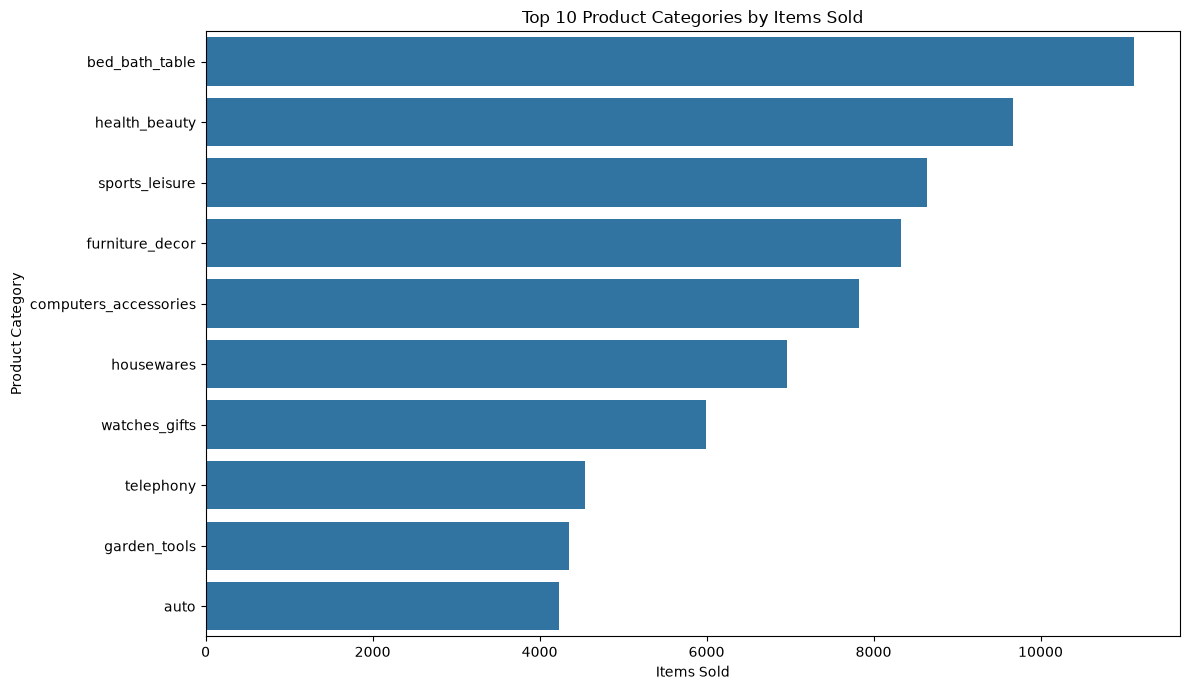

In [33]:
category_volume = (
    product_item_df
    .groupby("product_category_name_english")["order_item_id"]
    .count()
    .sort_values(ascending=False)
    .reset_index(name="items_sold")
)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=category_volume.head(10),
    y="product_category_name_english",
    x="items_sold"
)

plt.title("Top 10 Product Categories by Items Sold")
plt.xlabel("Items Sold")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

#### B. Top product categories by revenue

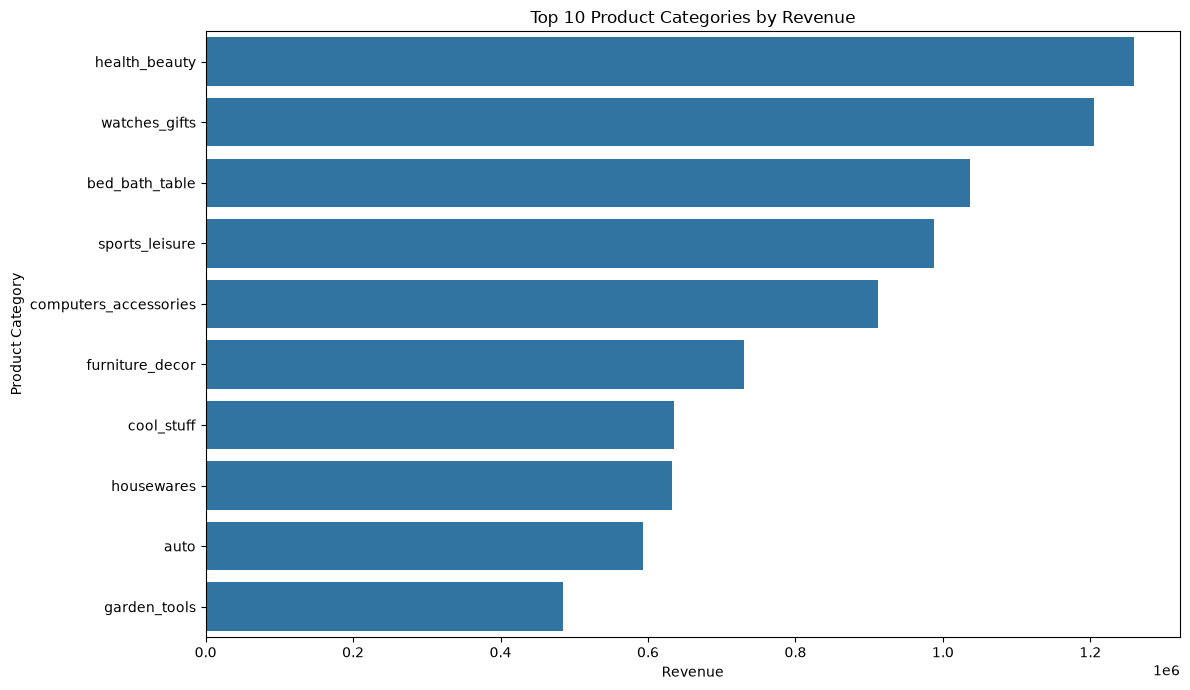

In [34]:
category_revenue = (
    product_item_df
    .groupby("product_category_name_english")["price"]
    .sum()
    .sort_values(ascending=False)
    .reset_index(name="revenue")
)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=category_revenue.head(10),
    y="product_category_name_english",
    x="revenue"
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

#### C. Number of unique products by category

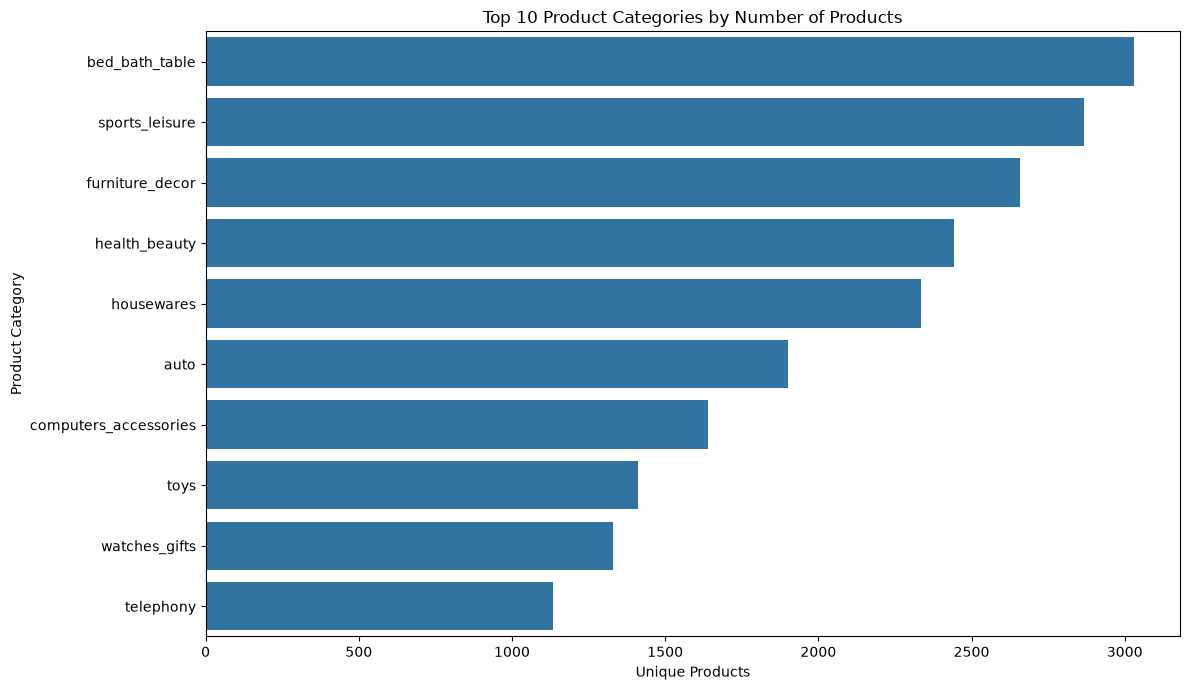

In [35]:
products_by_category = (
    products_eda
    .groupby("product_category_name_english")["product_id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="unique_products")
)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=products_by_category.head(10),
    y="product_category_name_english",
    x="unique_products"
)

plt.title("Top 10 Product Categories by Number of Products")
plt.xlabel("Unique Products")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

### 3.5 Summary

In [36]:
print("Dataset time range:")
print(
    orders_eda["order_purchase_timestamp"].min(),
    "to",
    orders_eda["order_purchase_timestamp"].max()
)

print("\nTotal orders:")
print(orders_eda["order_id"].nunique())

print("\nUnique customers:")
print(customers_eda["customer_unique_id"].nunique())

print("\nUnique sellers:")
print(sellers_eda["seller_id"].nunique())

print("\nUnique products:")
print(products_eda["product_id"].nunique())


print("\nTop 10 customer states:")
display(customers_by_state.head(10))

print("\nTop 10 seller states:")
display(sellers_by_state.head(10))

print("\nTop 10 product categories by sales volume:")
display(category_volume.head(10))

print("\nTop 10 product categories by revenue:")
display(category_revenue.head(10))

print("\nTop 10 product categories by number of products:")
display(products_by_category.head(10))

Dataset time range:
2016-09-04 21:15:19 to 2018-10-17 17:30:18

Total orders:
99441

Unique customers:
96096

Unique sellers:
3095

Unique products:
32951

Top 10 customer states:


,customer_state,unique_customers
0,SP,40302
1,RJ,12384
2,MG,11259
3,RS,5277
4,PR,4882
5,SC,3534
6,BA,3277
7,DF,2075
8,ES,1964
9,GO,1952



Top 10 seller states:


,seller_state,seller_count
0,SP,1849
1,PR,349
2,MG,244
3,SC,190
4,RJ,171
5,RS,129
6,GO,40
7,DF,30
8,ES,23
9,BA,19



Top 10 product categories by sales volume:


,product_category_name_english,items_sold
0,bed_bath_table,11115
1,health_beauty,9670
2,sports_leisure,8641
3,furniture_decor,8334
4,computers_accessories,7827
5,housewares,6964
6,watches_gifts,5991
7,telephony,4545
8,garden_tools,4347
9,auto,4235



Top 10 product categories by revenue:


,product_category_name_english,revenue
0,health_beauty,1258681.34
1,watches_gifts,1205005.68
2,bed_bath_table,1036988.68
3,sports_leisure,988048.97
4,computers_accessories,911954.32
5,furniture_decor,729762.49
6,cool_stuff,635290.85
7,housewares,632248.66
8,auto,592720.11
9,garden_tools,485256.46



Top 10 product categories by number of products:


,product_category_name_english,unique_products
0,bed_bath_table,3029
1,sports_leisure,2867
2,furniture_decor,2657
3,health_beauty,2444
4,housewares,2335
5,auto,1900
6,computers_accessories,1639
7,toys,1411
8,watches_gifts,1329
9,telephony,1134


## 4. Correlation and Relationship Exploration

### 4.1 Overall Numerical Correlation Analysis

To explore overall relationships among order value, freight cost, payment, delivery performance, and customer review score at the order level.

#### A. Data preparation

In [37]:
print("orders_eda:", orders_eda.shape)
print("order_items_eda:", order_items_eda.shape)
print("payments:", payments.shape)
print("reviews:", reviews.shape)

print("\nPayment columns:")
print(payments.columns.tolist())

orders_eda: (99441, 13)
order_items_eda: (112650, 7)
payments: (103886, 5)
reviews: (99224, 7)

Payment columns:
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']


In [38]:
order_item_summary = (
    order_items_eda
    .groupby("order_id")
    .agg(
        order_value=("price", "sum"),
        freight_value=("freight_value", "sum"),
        item_count=("order_item_id", "count")
    )
    .reset_index()
)

order_item_summary.head()

,order_id,order_value,freight_value,item_count
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,1
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,1
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,1
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,1


In [39]:
payment_summary = (
    payments
    .groupby("order_id")
    .agg(
        payment_value=("payment_value", "sum"),
        payment_installments=("payment_installments", "max")
    )
    .reset_index()
)

payment_summary.head()

,order_id,payment_value,payment_installments
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,2
1,00018f77f2f0320c557190d7a144bdd3,259.83,3
2,000229ec398224ef6ca0657da4fc703e,216.87,5
3,00024acbcdf0a6daa1e931b038114c75,25.78,2
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,3


In [40]:
reviews_eda = reviews.copy()

delivery_review_df = orders_eda.merge(
    reviews_eda[["order_id", "review_score"]],
    on="order_id",
    how="inner"
)

delivery_review_df[
    [
        "order_id",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "review_score"
    ]
].head()

,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18 00:00:00,4
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13 00:00:00,4
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04 00:00:00,5
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15 00:00:00,5
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26 00:00:00,5


Missing Value Check

In [41]:
c_cols = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "review_score"
]

missing_C = pd.DataFrame({
    "Missing Count": delivery_review_df[c_cols].isnull().sum(),
    "Missing Percentage (%)": delivery_review_df[c_cols].isnull().mean() * 100
})

display(missing_C.round(2))

,Missing Count,Missing Percentage (%)
order_purchase_timestamp,0,0.00
order_delivered_customer_date,2865,2.89
order_estimated_delivery_date,0,0.00
review_score,0,0.00


**Missing values:** `order_delivered_customer_date` contains 2,865 missing values (2.89%). Since the actual delivery date is required to measure delivery performance, these incomplete observations were excluded from this analysis.

In [42]:
delivery_review_clean = delivery_review_df.dropna(
    subset=["order_delivered_customer_date"]
).copy()

print(f"Rows before: {len(delivery_review_df)}")
print(f"Rows after: {len(delivery_review_clean)}")
print(f"Rows removed: {len(delivery_review_df) - len(delivery_review_clean)}")

Rows before: 99224
Rows after: 96359
Rows removed: 2865


Delivery Performance Measures

In [43]:
date_cols = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    delivery_review_clean[col] = pd.to_datetime(
        delivery_review_clean[col]
    )

# Actual delivery time from purchase to customer delivery
delivery_review_clean["delivery_days"] = (
    delivery_review_clean["order_delivered_customer_date"]
    - delivery_review_clean["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Difference between actual and estimated delivery date
delivery_review_clean["delay_days"] = (
    delivery_review_clean["order_delivered_customer_date"]
    - delivery_review_clean["order_estimated_delivery_date"]
).dt.total_seconds() / (24 * 60 * 60)

delivery_review_clean[
    ["delivery_days", "delay_days", "review_score"]
].describe().round(2)

,delivery_days,delay_days,review_score
count,96359.00,96359.00,96359.00
mean,12.52,-11.22,4.16
std,9.46,10.12,1.29
min,0.53,-146.02,1.00
25%,6.76,-16.25,4.00
50%,10.21,-11.97,5.00
75%,15.69,-6.41,5.00
max,208.35,188.98,5.00


In [44]:
delivery_summary = delivery_review_clean[
    [
        "order_id",
        "delivery_days",
        "delay_days",
        "review_score"
    ]
].copy()

delivery_summary.head()

,order_id,delivery_days,delay_days,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,-7.107488,4
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,-5.355729,4
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,-17.245498,5
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,-12.980069,5
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,-9.238171,5


In [45]:
overall_corr_df = (
    order_item_summary
    .merge(
        payment_summary,
        on="order_id",
        how="inner"
    )
    .merge(
        delivery_summary,
        on="order_id",
        how="inner"
    )
)

print("Shape:", overall_corr_df.shape)

overall_corr_df.head()

Shape: (96358, 9)


,order_id,order_value,freight_value,item_count,payment_value,payment_installments,delivery_days,delay_days,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,1,72.19,2,7.614421,-8.011250,5
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,1,259.83,3,16.216181,-2.330278,4
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,1,216.87,5,7.948437,-13.444954,5
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,1,25.78,2,6.147269,-5.435660,4
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,1,218.04,3,25.114352,-15.303808,5


Missing Value Check

In [46]:
overall_cols = [
    "order_value",
    "freight_value",
    "item_count",
    "payment_value",
    "payment_installments",
    "delivery_days",
    "delay_days",
    "review_score"
]

missing_overall = pd.DataFrame({
    "Missing Count":
        overall_corr_df[overall_cols].isnull().sum(),

    "Missing Percentage (%)":
        overall_corr_df[overall_cols].isnull().mean() * 100
})

display(missing_overall.round(2))

,Missing Count,Missing Percentage (%)
order_value,0,0.0
freight_value,0,0.0
item_count,0,0.0
payment_value,0,0.0
payment_installments,0,0.0
delivery_days,0,0.0
delay_days,0,0.0
review_score,0,0.0


#### B. Correlation Matrix

In [47]:
overall_corr_matrix = (
    overall_corr_df[overall_cols]
    .corr()
)

display(overall_corr_matrix.round(2))

,order_value,freight_value,item_count,payment_value,payment_installments,delivery_days,delay_days,review_score
order_value,1.00,0.41,0.15,1.00,0.31,0.06,-0.01,-0.03
freight_value,0.41,1.00,0.44,0.49,0.20,0.17,-0.05,-0.09
item_count,0.15,0.44,1.00,0.19,0.07,-0.02,-0.03,-0.12
payment_value,1.00,0.49,0.19,1.00,0.32,0.07,-0.02,-0.04
payment_installments,0.31,0.20,0.07,0.32,1.00,0.05,-0.03,-0.03
delivery_days,0.06,0.17,-0.02,0.07,0.05,1.00,0.60,-0.33
delay_days,-0.01,-0.05,-0.03,-0.02,-0.03,0.60,1.00,-0.27
review_score,-0.03,-0.09,-0.12,-0.04,-0.03,-0.33,-0.27,1.00


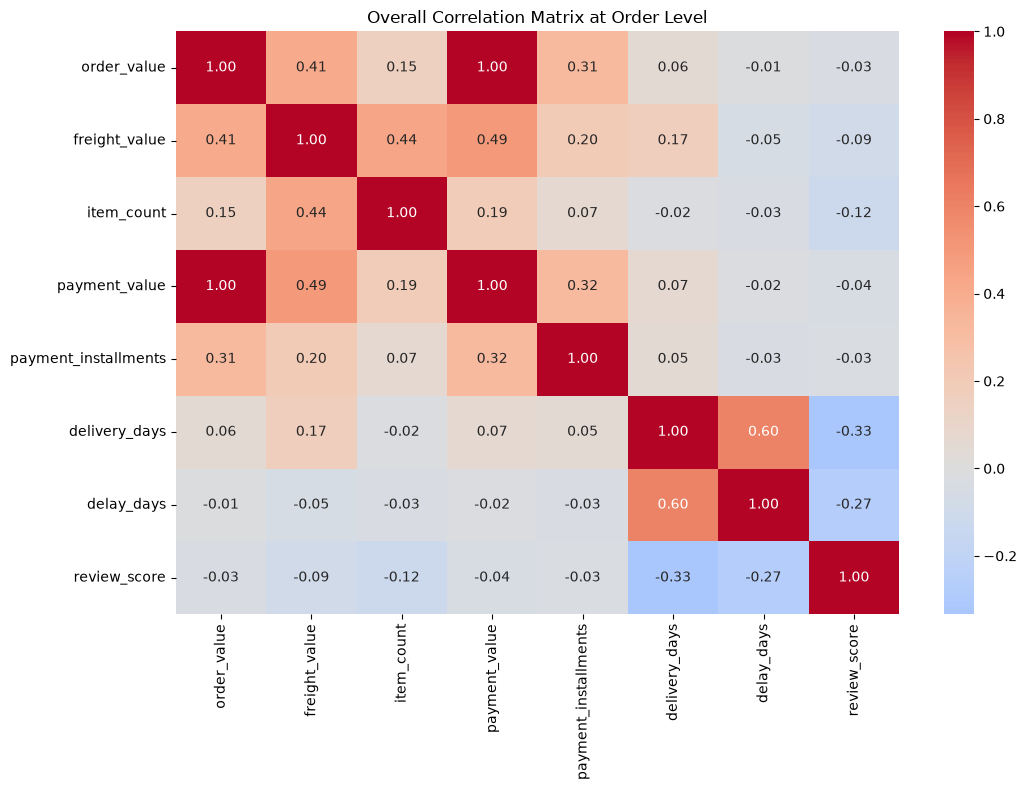

In [48]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    overall_corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Overall Correlation Matrix at Order Level")
plt.tight_layout()
plt.show()

### 4.2 Product and Freight Correlation Analysis

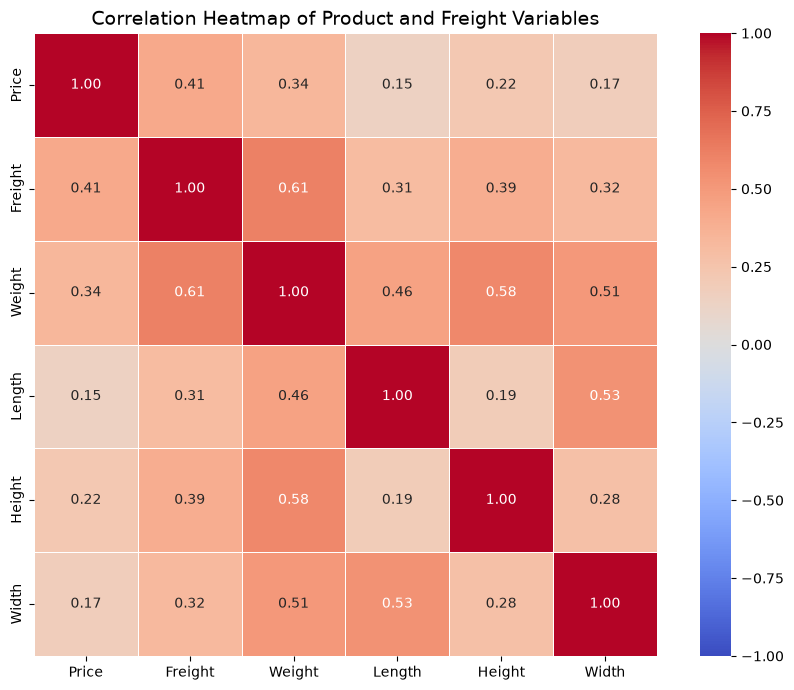

In [49]:
correlation_cols = [
    "price",
    "freight_value",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

# Calculate Pearson correlation matrix
corr_matrix = product_item_df[
    correlation_cols
].corr(method="pearson")

# Cleaner labels
labels = [
    "Price",
    "Freight",
    "Weight",
    "Length",
    "Height",
    "Width"
]

# Plot correlation heatmap
plt.figure(figsize=(9, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    xticklabels=labels,
    yticklabels=labels
)

plt.title(
    "Correlation Heatmap of Product and Freight Variables",
    fontsize=14
)

plt.tight_layout()
plt.show()

### 4.3 Key Relationship Exploration

#### A. Product Weight vs Freight Value

Missing Value Check

In [50]:
missing_A = pd.DataFrame({
    "Missing Count": product_item_df[
        ["product_weight_g", "freight_value"]
    ].isnull().sum(),

    "Missing Percentage (%)": product_item_df[
        ["product_weight_g", "freight_value"]
    ].isnull().mean() * 100
})

display(missing_A.round(2))

,Missing Count,Missing Percentage (%)
product_weight_g,18,0.02
freight_value,0,0.00


In [51]:
weight_freight_df = product_item_df[
    ["product_weight_g", "freight_value"]
].dropna()

original_corr = weight_freight_df[
    "product_weight_g"
].corr(weight_freight_df["freight_value"])

print(f"Pearson correlation: {original_corr:.3f}")

Pearson correlation: 0.610


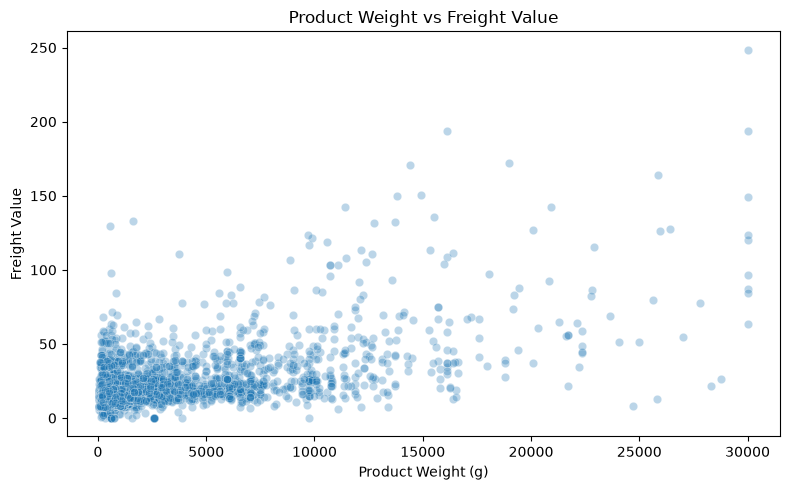

In [52]:
plot_sample = weight_freight_df.sample(
    n=min(5000, len(weight_freight_df)),
    random_state=42
)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=plot_sample,
    x="product_weight_g",
    y="freight_value",
    alpha=0.3
)

plt.title("Product Weight vs Freight Value")
plt.xlabel("Product Weight (g)")
plt.ylabel("Freight Value")
plt.tight_layout()
plt.show()

**Observation:** Product weight and freight value show a positive relationship (Pearson r = 0.610), suggesting that heavier products generally tend to have higher freight costs. However, several extreme observations are visible in the scatter plot.

Outlier and Robustness Check

In [53]:
def detect_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"{column}")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Number of outliers: {len(outliers)}")
    print(f"Outlier percentage: {len(outliers)/len(df)*100:.2f}%")
    print()

    return outliers


weight_outliers = detect_outliers_iqr(
    weight_freight_df,
    "product_weight_g"
)

freight_outliers = detect_outliers_iqr(
    weight_freight_df,
    "freight_value"
)

product_weight_g
Lower bound: -1950.00
Upper bound: 4050.00
Number of outliers: 15807
Outlier percentage: 14.03%

freight_value
Lower bound: 0.98
Upper bound: 33.25
Number of outliers: 12134
Outlier percentage: 10.77%



In [54]:
w_q1 = weight_freight_df["product_weight_g"].quantile(0.25)
w_q3 = weight_freight_df["product_weight_g"].quantile(0.75)
w_iqr = w_q3 - w_q1

f_q1 = weight_freight_df["freight_value"].quantile(0.25)
f_q3 = weight_freight_df["freight_value"].quantile(0.75)
f_iqr = f_q3 - f_q1

filtered_df = weight_freight_df[
    weight_freight_df["product_weight_g"].between(
        w_q1 - 1.5 * w_iqr,
        w_q3 + 1.5 * w_iqr
    )
    &
    weight_freight_df["freight_value"].between(
        f_q1 - 1.5 * f_iqr,
        f_q3 + 1.5 * f_iqr
    )
]

filtered_corr = filtered_df[
    "product_weight_g"
].corr(filtered_df["freight_value"])

print(f"Original correlation: {original_corr:.3f}")
print(f"Correlation without IQR outliers: {filtered_corr:.3f}")

Original correlation: 0.610
Correlation without IQR outliers: 0.316


**Key finding:** After excluding IQR-defined extreme observations, the correlation decreases from 0.610 to 0.316 but remains positive. This indicates that product weight is positively associated with freight value, although the strength of the original correlation is partly influenced by extreme observations.

#### B. Product Price vs Freight Value

To examine whether higher-priced products are associated with higher freight costs.

In [55]:
price_freight_df = product_item_df[
    ["price", "freight_value"]
].dropna()

price_freight_corr = price_freight_df[
    "price"
].corr(price_freight_df["freight_value"])

print(f"Pearson correlation: {price_freight_corr:.3f}")

Pearson correlation: 0.414


Missing Value Check

In [56]:
product_item_df[
    ["price", "freight_value"]
].isnull().sum()

price            0
freight_value    0
dtype: int64

No missing values were found in the variables used for this analysis.

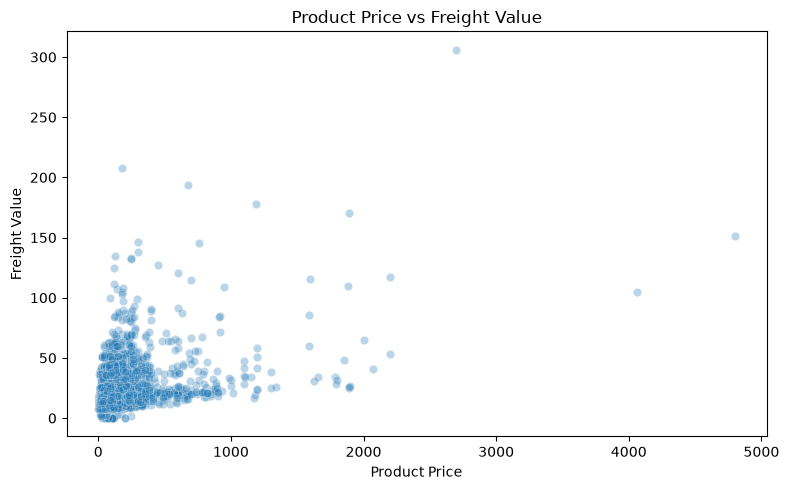

In [57]:
plot_sample = price_freight_df.sample(
    n=min(5000, len(price_freight_df)),
    random_state=42
)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=plot_sample,
    x="price",
    y="freight_value",
    alpha=0.3
)

plt.title("Product Price vs Freight Value")
plt.xlabel("Product Price")
plt.ylabel("Freight Value")
plt.tight_layout()
plt.show()

Key finding: Product price is positively associated with freight value (r = 0.414). After excluding IQR-defined extreme observations, the correlation decreases to 0.307 but remains positive, suggesting that the relationship is not solely driven by extreme values.

Outlier and Robustness Check

In [58]:
q1 = price_freight_df.quantile(0.25)
q3 = price_freight_df.quantile(0.75)
iqr = q3 - q1

filtered_price_freight = price_freight_df[
    ((price_freight_df >= q1 - 1.5 * iqr) &
     (price_freight_df <= q3 + 1.5 * iqr)).all(axis=1)
]

filtered_corr = filtered_price_freight[
    "price"
].corr(filtered_price_freight["freight_value"])

print(f"Original correlation: {price_freight_corr:.3f}")
print(f"Correlation without IQR outliers: {filtered_corr:.3f}")

Original correlation: 0.414
Correlation without IQR outliers: 0.307


#### C. Delivery Performance vs Review Score

Delivery Time by Review Score

In [59]:
delivery_by_review = (
    delivery_review_clean
    .groupby("review_score")["delivery_days"]
    .agg(["mean", "median", "count"])
    .round(2)
)

display(delivery_by_review)

,mean,median,count
review_score,,,
1,21.31,16.78,9409
2,16.66,13.25,2941
3,14.26,12.05,7962
4,12.31,10.79,18987
5,10.69,9.24,57060


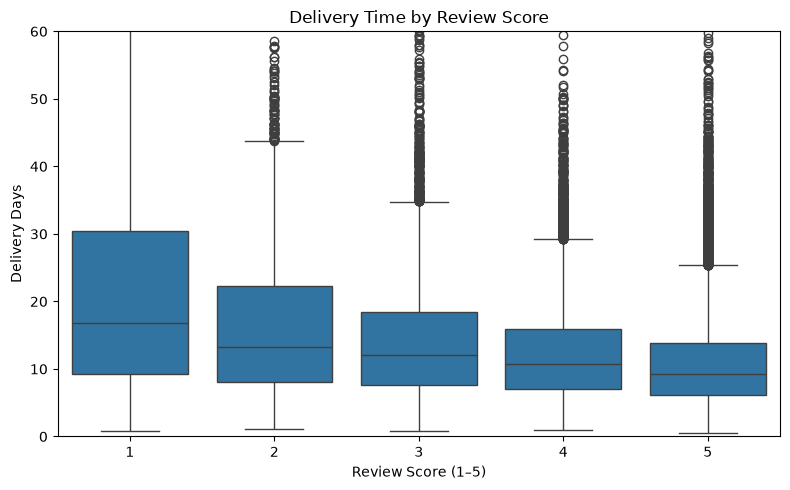

In [60]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=delivery_review_clean,
    x="review_score",
    y="delivery_days"
)

plt.title("Delivery Time by Review Score")
plt.xlabel("Review Score (1–5)")
plt.ylabel("Delivery Days")
plt.ylim(0, 60)

plt.tight_layout()
plt.show()

Observation: Lower-rated orders generally have longer delivery times, while higher review scores are associated with shorter delivery times.

Review Score by Delivery Status

In [61]:
delivery_review_clean["delivery_status"] = np.where(
    delivery_review_clean["delay_days"] > 0,
    "Late",
    "On Time / Early"
)

review_by_status = (
    delivery_review_clean
    .groupby("delivery_status")["review_score"]
    .agg(["mean", "median", "count"])
    .round(2)
)

display(review_by_status)

,mean,median,count
delivery_status,,,
Late,2.57,2.0,7701
On Time / Early,4.29,5.0,88658


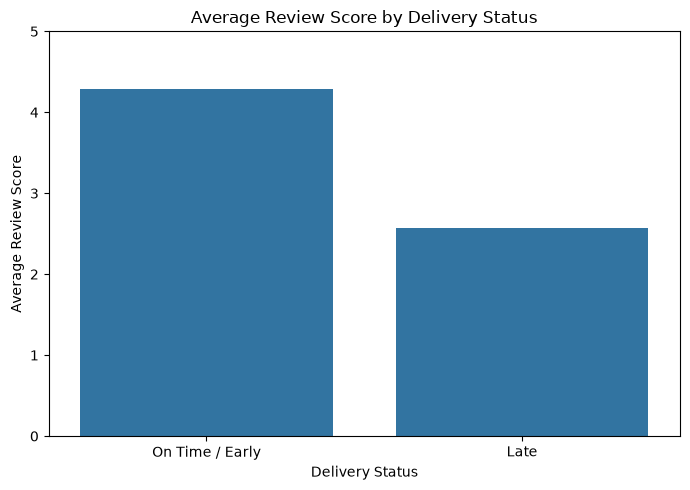

In [62]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=delivery_review_clean,
    x="delivery_status",
    y="review_score",
    errorbar=None
)

plt.title("Average Review Score by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

Key finding: Late deliveries received substantially lower review scores (mean = 2.57) than orders delivered on time or early (mean = 4.29). This indicates a strong association between delivery performance and customer satisfaction.

### 4.3 Key Findings

Product weight shows the strongest association with freight value among the examined product variables (r = 0.61), although the relationship weakens after excluding IQR-defined extreme observations.

Product price is also positively associated with freight value (r = 0.41), but the relationship is weaker than that of product weight.

Delivery performance shows a clear relationship with customer satisfaction: longer and late deliveries are associated with substantially lower review scores.